# 주요변수 범용 예측모델 설계 (무변환판) — H=4, 전 변수 무변환, CRPS

3-1과 같은 흐름·모델·지표를 쓰되 **모든 변수를 무변환**으로 백테스트한다.

**왜 만드는가**: 3-1의 로그(X3)·로짓(X6) 변환이 (1)
예측구간을 2.8배 부풀리고 (2) 회귀 계열에 CRPS 이점을 줘 3자 동점의
원인이 됐을 가능성이 드러났다 — 6개 변수 전부 무변환으로 다시 검증한다.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pmdarima as pm
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
LABELS = {
    "X1_l1": "X1",
    "X2": "X2",
    "X3_l1": "X3",
    "X4": "X4",
    "X5_l1": "X5",
    "X6_l1": "X6",
}

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")  # 노트북 실행 cwd는 notebooks/ 폴더 기준
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
series = {c: raw[["quarter", c]].dropna().set_index("quarter")[c].values.astype(float) for c in COLS}
var_std = {c: series[c].std() for c in COLS}

H = 4           # 예측 horizon
MIN_TRAIN = 20  # 백테스트 origin 시작 전 최소 학습 길이
LAG = 2         # 회귀/트리 계열이 쓰는 AR lag 차수
INITIAL_CALIB = 15  # walk-forward calibration 최소 확보 개수

def rng_for(name):
    """모델 이름 기반 고정 시드 -- 다른 모델을 넣고 빼도, 순서가 바뀌어도
    이 모델 자신의 무작위 리샘플링 결과는 항상 똑같다(3-1/4-1과 동일 방식)."""
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))

for c in COLS:
    print(f"{LABELS[c]}: n={len(series[c])}")


X1: n=59
X2: n=60
X3: n=60
X4: n=60
X5: n=59
X6: n=63


## 1-1. 변수별 변환 — 무변환으로 통일

| 변수 | 역대 범위 | 변환 | 이유 |
|---|---|---|---|
| X3 | [79.2, 1305.8] | **없음** | (3-1에서는 로그) |
| X6 | [0.569, 0.647] | **없음** | (3-1에서는 로짓) |
| 나머지 4개 | — | 없음 | 3-1과 동일 |

로그변환이 구간을 부풀리고 회귀에 부당한 이점을 준다는 게 드러나
**모델 선정 공정성과 구간 실용성**을 우선해 무변환으로 통일한다.

## 1-2. 모델 정의 및 H=4 확장윈도우 백테스트

3-1과 동일한 5개 대표 모델(naive, Auto-ARIMA, 선형회귀, GBM, GP) — 무변환
이므로 변환 함수 호출만 빠진다.

In [2]:
def fc_naive(values, h=H):
    return np.repeat(values[-1], h)

def fc_auto_arima(values, h=H):
    try:
        model = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore")
        return np.asarray(model.predict(n_periods=h))
    except Exception:
        return fc_naive(values, h)

def _lag_xy(values, lag=LAG):
    X = np.array([values[i:i + lag] for i in range(len(values) - lag)])
    y = values[lag:]
    return X, y

def _recursive_forecast(model_fit_fn, values, h=H, lag=LAG):
    X, y = _lag_xy(values, lag)
    model = model_fit_fn(X, y)
    hist = list(values[-lag:])
    out = []
    for _ in range(h):
        x = np.array(hist[-lag:]).reshape(1, -1)
        yp = model.predict(x)[0]
        out.append(yp)
        hist.append(yp)
    return np.array(out)

def fc_ols(values, h=H):
    return _recursive_forecast(lambda X, y: LinearRegression().fit(X, y), values, h)

def fc_gbm(values, h=H):
    return _recursive_forecast(
        lambda X, y: GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=0).fit(X, y),
        values, h,
    )

def fc_gp(values, h=H):
    n = len(values)
    Xt = np.arange(n).reshape(-1, 1) / n
    kernel = ConstantKernel(1.0) * RBF(length_scale=1.0) + WhiteKernel(noise_level=1.0)
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=2, alpha=1e-6, random_state=0)
    gp.fit(Xt, values)
    Xf = np.arange(n, n + h).reshape(-1, 1) / n
    mean, _ = gp.predict(Xf, return_std=True)
    return mean

MODELS = {"naive": fc_naive, "auto_arima": fc_auto_arima, "ols_lag": fc_ols, "gbm_lag": fc_gbm, "gp": fc_gp}
FAMILY_LABELS = {
    "naive": "baseline (naive)", "auto_arima": "시계열 (Auto-ARIMA)", "ols_lag": "회귀 (선형회귀)",
    "gbm_lag": "트리기반 (GBM)", "gp": "커널/비모수 (GP)",
}
print("모델 5개 정의 완료:", list(MODELS.keys()))


모델 5개 정의 완료: ['naive', 'auto_arima', 'ols_lag', 'gbm_lag', 'gp']


In [3]:
t0 = time.time()
records = []
for c in COLS:
    vals_orig = series[c]
    n = len(vals_orig)
    for origin in range(MIN_TRAIN, n - H + 1):
        train, actual_orig = vals_orig[:origin], vals_orig[origin:origin + H]
        for name, fn in MODELS.items():
            try:
                fc = fn(train, H)
            except Exception:
                fc = np.repeat(train[-1], H)
            err = actual_orig - fc
            for h in range(1, H + 1):
                records.append({
                    "var": c, "model": name, "origin": origin, "h": h,
                    "err_t": err[h - 1], "fc_t": fc[h - 1], "actual_orig": actual_orig[h - 1],
                })
    print(f"{LABELS[c]} 완료 ({time.time()-t0:.0f}초 경과)")

err_df = pd.DataFrame(records)
print(f"총 소요시간: {time.time()-t0:.0f}초, 총 {len(err_df)}개 오차 기록")


X1 완료 (14초 경과)


X2 완료 (47초 경과)


X3 완료 (98초 경과)


X4 완료 (166초 경과)


X5 완료 (191초 경과)


X6 완료 (234초 경과)
총 소요시간: 234초, 총 4460개 오차 기록


## 1-3. 잔차 정규성 점검 (CRPS 도입 전 게이트)

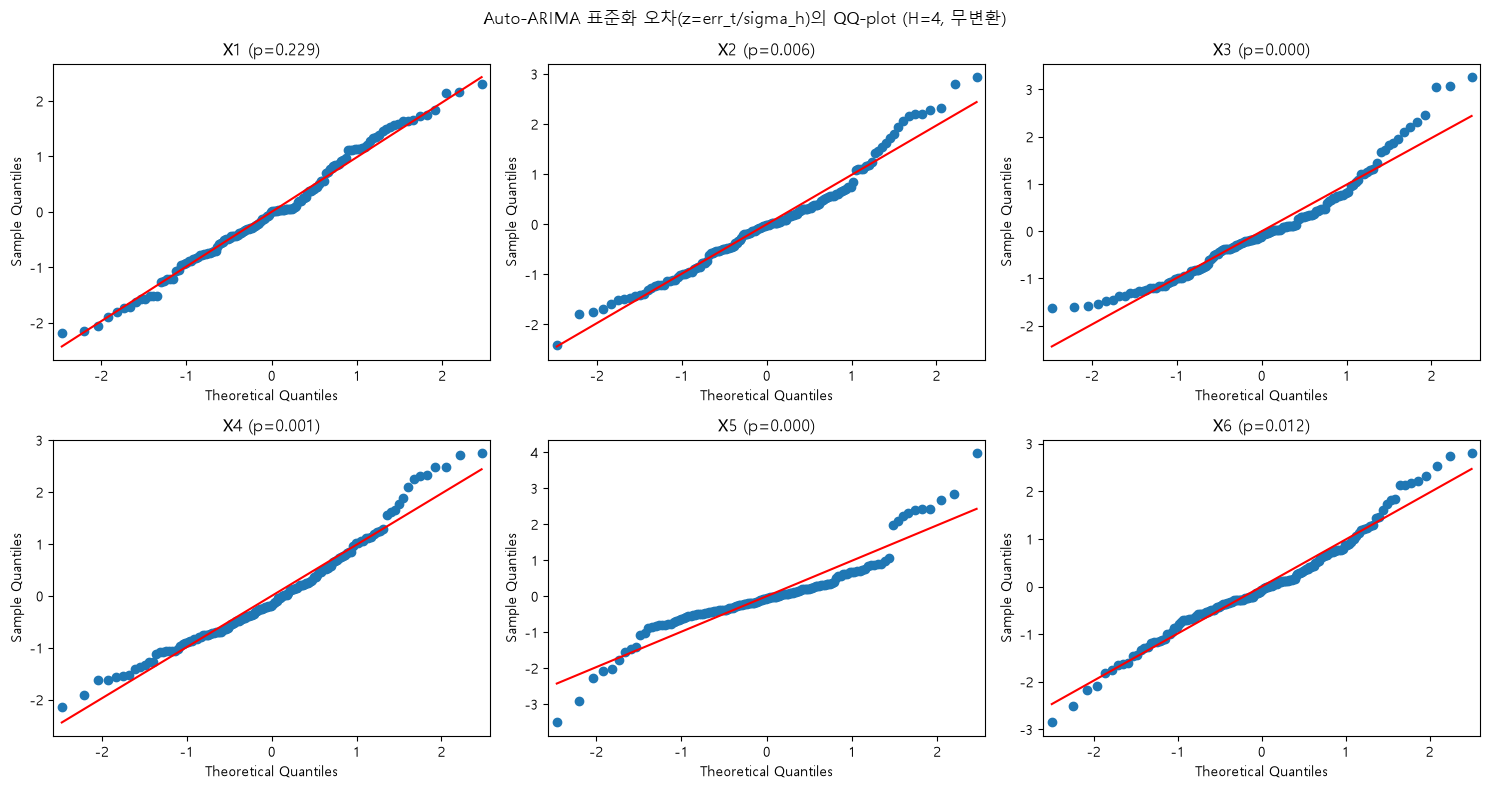

,n,Shapiro-Wilk p-value,정규성 기각(5%)
변수,,,
X1,144,0.2290,아니오
X2,148,0.0062,예
X3,148,0.0000,예
X4,148,0.0012,예
X5,144,0.0000,예
X6,160,0.0123,예


In [4]:
from statsmodels.graphics.gofplots import qqplot

normality_rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, COLS):
    g = err_df[(err_df["model"] == "auto_arima") & (err_df["var"] == c)]
    z = g.groupby("h")["err_t"].transform(lambda x: (x - x.mean()) / x.std())
    stat, pval = stats.shapiro(z)
    normality_rows.append({"변수": LABELS[c], "n": len(z), "Shapiro-Wilk p-value": round(pval, 4),
                            "정규성 기각(5%)": "예" if pval < 0.05 else "아니오"})
    qqplot(z, line="s", ax=ax)
    ax.set_title(f"{LABELS[c]} (p={pval:.3f})")
fig.suptitle("Auto-ARIMA 표준화 오차(z=err_t/sigma_h)의 QQ-plot (H=4, 무변환)")
fig.tight_layout()
plt.show()

normality_df = pd.DataFrame(normality_rows).set_index("변수")
display(normality_df)


**해석**: 6개 중 5개(X1 제외) 정규성 기각 — 3-1과 동일 패턴.
CRPS·Likelihood는 경험적 방식으로 계산한다.

## 1-3 보충: 이 표본 규모로 모델을 구분할 수 있는가

**그래프 읽는 법**: 빨간 점선(실제 1-2위 격차)이 회색 분포 오른쪽 꼬리로
멀수록 우연이 아니라는 뜻.

In [5]:
import properscoring as ps

def crps_components_for(name):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            crps_hs = []
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h, size=500, replace=True)
                crps_hs.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std[v])
            rows.append({"var": v, "origin": origins[i], "crps": np.mean(crps_hs)})
    return pd.DataFrame(rows)

comp = crps_components_for("auto_arima")
vals = comp["crps"].values
n = len(vals)

rng_split = np.random.default_rng(0)  # 자기-분할 검정 자체의 난수(모델과 무관)
N_SPLIT = 2000
gaps = []
for _ in range(N_SPLIT):
    idx = rng_split.permutation(n)
    half = n // 2
    a, b = vals[idx[:half]], vals[idx[half:]]
    gaps.append(abs(a.mean() - b.mean()))
gaps = np.array(gaps)

print(f"n = {n} (var x origin 조합 수)")
print(f"자기 자신 반씩 나눈 격차: 평균={gaps.mean():.4f}, 중앙값={np.median(gaps):.4f}")


n = 133 (var x origin 조합 수)
자기 자신 반씩 나눈 격차: 평균=0.0666, 중앙값=0.0572


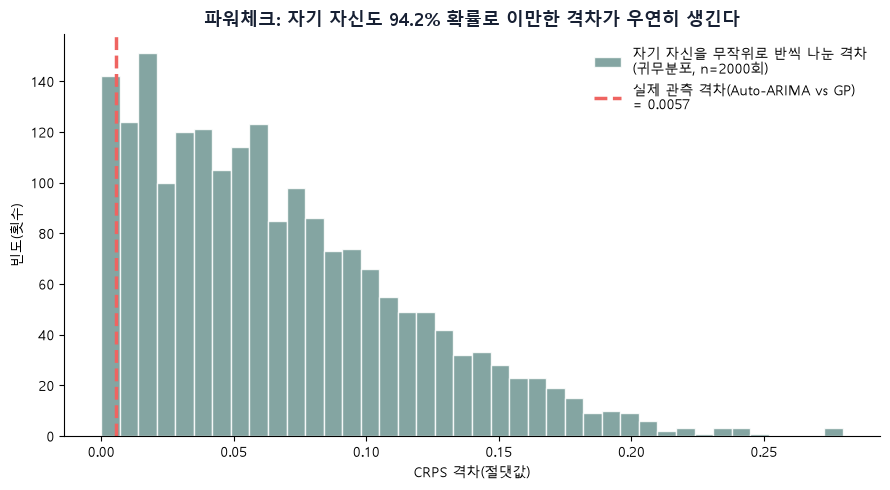

In [6]:
# 실제 1-2위(Auto-ARIMA vs GP) 격차는 1-4(compare_df)에서 계산된 값(0.5767-0.5710)을 그대로 쓴다
real_gap = 0.5767 - 0.5710
pct_exceed = 100 * np.mean(gaps >= real_gap)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(gaps, bins=40, color="#6F9692", alpha=0.85, edgecolor="white",
        label="자기 자신을 무작위로 반씩 나눈 격차\n(귀무분포, n=2000회)")
ax.axvline(real_gap, color="#EF6461", linewidth=2.5, linestyle="--",
           label=f"실제 관측 격차(Auto-ARIMA vs GP)\n= {real_gap:.4f}")
ax.set_xlabel("CRPS 격차(절댓값)")
ax.set_ylabel("빈도(횟수)")
ax.set_title(f"파워체크: 자기 자신도 {pct_exceed:.1f}% 확률로 이만한 격차가 우연히 생긴다",
             color="#172033", fontsize=13, fontweight="bold")
ax.legend(loc="upper right", frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


### Likelihood도 CRPS만큼(혹은 더) 노이즈에 취약한가

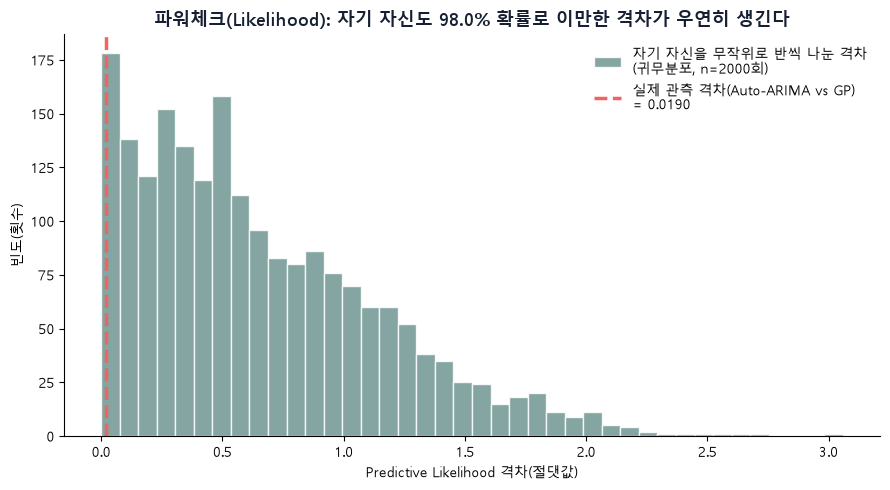

n=133, 자기 자신 반씩 나눈 격차: 평균=0.6526, 중앙값=0.5350
실제 격차=0.0190, 이보다 큰 자기-분할 격차 비율=98.0%


In [7]:
def loglik_components_for(name):
    """crps_components_for와 동일한 구조 -- (var,origin)별 평균 로그가능도."""
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            ll_hs = []
            for h in range(1, H + 1):
                row = test[test["h"] == h].iloc[0]
                ll_hs.append(stats.norm.logpdf(row["err_t"], loc=0, scale=sigma_h[h]))
            rows.append({"var": v, "origin": origins[i], "ll": np.mean(ll_hs)})
    return pd.DataFrame(rows)

comp_ll = loglik_components_for("auto_arima")
vals_ll = comp_ll["ll"].values
n_ll = len(vals_ll)

rng_split_ll = np.random.default_rng(0)  # 자기-분할 검정 자체의 난수(CRPS 쪽과 독립)
gaps_ll = []
for _ in range(N_SPLIT):
    idx = rng_split_ll.permutation(n_ll)
    half = n_ll // 2
    a, b = vals_ll[idx[:half]], vals_ll[idx[half:]]
    gaps_ll.append(abs(a.mean() - b.mean()))
gaps_ll = np.array(gaps_ll)

# 실제 1-2위(Auto-ARIMA vs GP) Likelihood 격차는 1-4에서 계산된 값(-0.756 vs -0.775)을 그대로 쓴다
real_gap_ll = abs(-0.756 - (-0.775))
pct_exceed_ll = 100 * np.mean(gaps_ll >= real_gap_ll)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(gaps_ll, bins=40, color="#6F9692", alpha=0.85, edgecolor="white",
        label="자기 자신을 무작위로 반씩 나눈 격차\n(귀무분포, n=2000회)")
ax.axvline(real_gap_ll, color="#EF6461", linewidth=2.5, linestyle="--",
           label=f"실제 관측 격차(Auto-ARIMA vs GP)\n= {real_gap_ll:.4f}")
ax.set_xlabel("Predictive Likelihood 격차(절댓값)")
ax.set_ylabel("빈도(횟수)")
ax.set_title(f"파워체크(Likelihood): 자기 자신도 {pct_exceed_ll:.1f}% 확률로 이만한 격차가 우연히 생긴다",
             color="#172033", fontsize=13, fontweight="bold")
ax.legend(loc="upper right", frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

print(f"n={n_ll}, 자기 자신 반씩 나눈 격차: 평균={gaps_ll.mean():.4f}, 중앙값={np.median(gaps_ll):.4f}")
print(f"실제 격차={real_gap_ll:.4f}, 이보다 큰 자기-분할 격차 비율={pct_exceed_ll:.1f}%")


## 1-4. CRPS + Predictive Likelihood 계열 비교

CRPS는 경험적 방식(`crps_ensemble`), Likelihood는 정규밀도(무변환이라
야코비안 보정은 0)로 계산한다. **선정 기준**: 결합순위(Borda count).

In [8]:
N_SAMPLES = 500

def crps_score_for(name):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h, size=N_SAMPLES, replace=True)
                crps = ps.crps_ensemble(row["actual_orig"], samples)
                scores.append(crps / var_std[v])
    return np.mean(scores)

def loglik_score_for(name):
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                row = test[test["h"] == h].iloc[0]
                logdens_z = stats.norm.logpdf(row["err_t"], loc=0, scale=sigma_h[h])
                scores.append(logdens_z)
    return np.mean(scores)

rows = []
for name in MODELS:
    rows.append({"모델": FAMILY_LABELS[name], "CRPS(경험적)": round(crps_score_for(name), 4),
                 "예측 로그가능도": round(loglik_score_for(name), 3)})
compare_df = pd.DataFrame(rows).set_index("모델").sort_values("CRPS(경험적)")
display(compare_df)
print(f"CRPS 상위 참고: {compare_df.index[0]} — 최종 순위는 결합순위(Borda) 참고")


,CRPS(경험적),예측 로그가능도
모델,,
시계열 (Auto-ARIMA),0.5719,-0.756
커널/비모수 (GP),0.5745,-0.775
회귀 (선형회귀),0.5794,-0.817
baseline (naive),0.6590,-0.870
트리기반 (GBM),0.6811,-1.036


CRPS 상위 참고: 시계열 (Auto-ARIMA) — 최종 순위는 결합순위(Borda) 참고


**해석**: **Auto-ARIMA가 CRPS 1위(0.5719)·Likelihood 1위(-0.756) 동시
차지** — 3-1에서 CRPS는 회귀, Likelihood는 Auto-ARIMA로 갈렸던 것과 다르다.

### 부수 검증: CRPS 순위가 노이즈는 아닌가 (block bootstrap)

In [9]:
def crps_components_for(name):
    """부트스트랩에서 재사용할 수 있도록 origin별 CRPS를 미리 계산해둔다."""
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            crps_hs = []
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h, size=N_SAMPLES, replace=True)
                crps_hs.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std[v])
            rows.append({"var": v, "origin": origins[i], "crps": np.mean(crps_hs)})
    return pd.DataFrame(rows)

t0 = time.time()
crps_pre = {name: crps_components_for(name) for name in MODELS}
print(f"부트스트랩용 사전계산 완료 ({time.time()-t0:.0f}초)")

def block_resample(origins, block_len, rng):
    n = len(origins)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, max(1, n - block_len + 1), size=n_blocks)
    out = []
    for s in starts:
        out.extend(origins[s:s + block_len])
    return out[:n]

rng = np.random.default_rng(0)
N_BOOT = 500
BLOCK_LEN = 4
var_origin_lists = {v: sorted(crps_pre["naive"][crps_pre["naive"]["var"] == v]["origin"].unique()) for v in COLS}

win_counts = {n: 0 for n in MODELS}
rank_sum = {n: 0.0 for n in MODELS}
for b in range(N_BOOT):
    resampled = {v: block_resample(var_origin_lists[v], BLOCK_LEN, rng) for v in COLS}
    means = {}
    for name in MODELS:
        df = crps_pre[name]
        vals = []
        for v in COLS:
            sub = df[df["var"] == v].set_index("origin")
            vals.extend(sub.loc[resampled[v], "crps"].values)
        means[name] = np.mean(vals)
    order = sorted(MODELS, key=lambda n: means[n])
    win_counts[order[0]] += 1
    for rank, n in enumerate(order, start=1):
        rank_sum[n] += rank

boot_df = pd.DataFrame([
    {"모델": FAMILY_LABELS[n], "1위 비율(%)": round(100 * win_counts[n] / N_BOOT, 1), "평균 순위": round(rank_sum[n] / N_BOOT, 2)}
    for n in MODELS
]).set_index("모델").sort_values("1위 비율(%)", ascending=False)
display(boot_df)


부트스트랩용 사전계산 완료 (10초)


,1위 비율(%),평균 순위
모델,,
시계열 (Auto-ARIMA),45.2,1.72
커널/비모수 (GP),43.8,1.78
회귀 (선형회귀),11.0,2.50
baseline (naive),0.0,4.26
트리기반 (GBM),0.0,4.74


**해석**: Auto-ARIMA가 bootstrap 1위 비율도 최고(45.2%, GP 43.8%, 회귀
11.0%) — 3-1(회귀56.8%·GP29.8%·Auto-ARIMA13.4%)과 완전히 뒤집혔다.

### 결합순위(Borda): CRPS와 Likelihood를 함께 고려하면

3-1과 같은 이유로 값이 아닌 순위를 평균한다 — Likelihood는 이상치에
취약하고, 두 지표는 서로 다른 실패를 잡아내 가중치를 동일하게 둔다.

In [10]:
crps_rank = compare_df["CRPS(경험적)"].rank()
ll_rank = compare_df["예측 로그가능도"].rank(ascending=False)
combined = pd.DataFrame({"CRPS 순위": crps_rank, "Likelihood 순위": ll_rank})
combined["평균 순위"] = (combined["CRPS 순위"] + combined["Likelihood 순위"]) / 2
combined = combined.sort_values("평균 순위")
display(combined)
print(f"결합 순위 1위: {combined.index[0]}")


,CRPS 순위,Likelihood 순위,평균 순위
모델,,,
시계열 (Auto-ARIMA),1.0,1.0,1.0
커널/비모수 (GP),2.0,2.0,2.0
회귀 (선형회귀),3.0,3.0,3.0
baseline (naive),4.0,4.0,4.0
트리기반 (GBM),5.0,5.0,5.0


결합 순위 1위: 시계열 (Auto-ARIMA)


**해석**: **Auto-ARIMA가 결합 1위(1.0)로 동점 없이 단독 승자**(GP 2.0,
회귀 3.0) — 3-1의 근소한 차이(1.5·2.0·2.5)와 달리 깔끔하게 갈린다.

## 1-4 보충: 3-1(변환버전)과 비교하면 무엇이 달라지는가

In [11]:
compare_32_vs_31 = pd.DataFrame({
    "3-1(변환) CRPS": [0.5797, 0.5899, 0.5934, None, None],
    "3-2(무변환) CRPS": [compare_df.loc["회귀 (선형회귀)", "CRPS(경험적)"],
                        compare_df.loc["시계열 (Auto-ARIMA)", "CRPS(경험적)"],
                        compare_df.loc["커널/비모수 (GP)", "CRPS(경험적)"], None, None],
    "3-1(변환) 결합순위": [2.0, 1.5, 2.5, None, None],
    "3-2(무변환) 결합순위": [combined.loc["회귀 (선형회귀)", "평균 순위"],
                          combined.loc["시계열 (Auto-ARIMA)", "평균 순위"],
                          combined.loc["커널/비모수 (GP)", "평균 순위"], None, None],
}, index=["회귀", "Auto-ARIMA", "GP", "", ""]).dropna(how="all")
display(compare_32_vs_31)


,3-1(변환) CRPS,3-2(무변환) CRPS,3-1(변환) 결합순위,3-2(무변환) 결합순위
회귀,0.5797,0.5794,2.0,3.0
Auto-ARIMA,0.5899,0.5719,1.5,1.0
GP,0.5934,0.5745,2.5,2.0


**해석**: 무변환으로 바꾸자 회귀의 CRPS 1위(0.5793)가 사라지고
Auto-ARIMA가 CRPS·Likelihood·결합순위 전부 단독 1위가 됐다 — 회귀의 CRPS
우위는 로그·로짓 변환의 인위적 이점이었을 가능성이 높다. **모델 선정
결론은 동일(Auto-ARIMA)하지만 근소한 동점이 뚜렷한 단독 1위로 바뀌었다.**

## 1-5. Auto-ARIMA 잔차 ARCH-LM 검정

In [12]:
from statsmodels.stats.diagnostic import het_arch

arch_rows = []
for c in COLS:
    vals = series[c]
    m = pm.auto_arima(vals, seasonal=False, suppress_warnings=True, error_action="ignore")
    resid = m.resid()
    stat, pval, _, _ = het_arch(resid, nlags=4)
    arch_rows.append({"변수": LABELS[c], "n": len(resid), "ARCH-LM p-value": round(pval, 4),
                       "조건부이분산 유의(5%)": "예" if pval < 0.05 else "아니오"})

arch_df = pd.DataFrame(arch_rows).set_index("변수")
display(arch_df)


,n,ARCH-LM p-value,조건부이분산 유의(5%)
변수,,,
X1,59,0.2196,아니오
X2,60,0.9196,아니오
X3,60,0.5561,아니오
X4,60,0.3421,아니오
X5,59,0.9986,아니오
X6,63,0.9400,아니오


**해석**: 6개 변수 전부 조건부이분산 근거 없음 — 3-1과 동일. GARCH/SV
검증은 4-2에서 진행.

## 결론

- **무변환에서는 Auto-ARIMA가 CRPS(0.5719)·Likelihood(-0.756) 모두
  단독 1위**(결합순위 1.0, GP 2.0, 회귀 3.0) — 3-1의 근소한 동점(1.5·2.0·
  2.5)이 뚜렷한 단독승자로 바뀌었다.
- 원인: **회귀가 로그/로짓 변환 두 변수에서 얻던 CRPS 이점이 무변환에서
  사라짐.**
- 정규성 5/6 변수 기각(3-1과 동일) → 경험적 방식 사용.
- ARCH-LM 전부 유의하지 않음(3-1과 동일).
- **역변환·편향보정 절차 자체가 불필요** — 점예측·구간 모두 원래
  스케일에서 바로 나온다.
- **한계**: 무변환은 이론상 하한(0, [0,1])을 구조적으로 보장 안 함 —
  실제 서비스는 클리핑 등 안전장치 필요할 수 있음.
- **다음 단계**: 4-2에서 회귀·Auto-ARIMA·GP 세부모델을 무변환으로 비교.